# SAMap transferred-annotation object — full visualization

Reads a finished `*_transferred.h5ad` and plots every transfer that's on it: coarse dec/fib, fine
subtype (mouse->human), and pseudotime (mouse native + human transferred). Plots straight off `obs`
— small file, no pkl, no recompute. This is the collaborator-facing notebook.

**Kernel:** any env with scanpy/anndata (`rsc_uv` is fine — no samap/gcc needed, it only reads an h5ad).

**Columns it uses** (written by `make_transferred_object.py`):
`species`, `cell_type_independent`, `cell_type_transferred`, `transferred_frac_decidual`,
`cell_subtype`, `cell_subtype_transferred`, `cell_subtype_transferred_frac`,
`pseudotime`, `pseudotime_source`; `obsm['X_umap']` (joint, co-registered) and `obsm['spatial']`
(per-species — subset before plotting).

## Config + load

In [8]:
%matplotlib inline
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

RESULTS = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/samap_transfer"
RUN = "secretory_x_1dpi_late_hmmer"          # or "secretory_x_1dpi_late_hmmer"

a = ad.read_h5ad(f"{RESULTS}/{RUN}_transferred.h5ad")
is_h = (a.obs["species"].astype(str) == "hs").values
is_m = (a.obs["species"].astype(str) == "mm").values
U  = np.asarray(a.obsm["X_umap"]); XY = np.asarray(a.obsm["spatial"])
print(a.shape, "| human", int(is_h.sum()), "mouse", int(is_m.sum()))
print("obs:", [c for c in a.obs.columns if not c.startswith(("hs_","mm_","leiden"))])

# a stable color map for the 9 mouse fine subtypes (so mouse-native & human-transferred match)
SUBTYPES = ["eFib1","eFib2","eFib2i","eFib3","eFibP","dec1","dec2","dec3","decAp"]
_cols = plt.get_cmap("tab20").colors
SUB_COLORS = {s: _cols[i % 20] for i, s in enumerate(SUBTYPES)}
def cat_colors(cats): return [SUB_COLORS.get(str(c), (0.8,0.8,0.8)) for c in cats]

(34228, 70299) | human 23441 mouse 10787
obs: ['batch', 'species', 'cell_type_independent', 'cell_type_transferred', 'transferred_frac_decidual', 'cell_subtype', 'cell_subtype_transferred', 'cell_subtype_transferred_frac', 'pseudotime', 'pseudotime_source']


## Helper: colored UMAP panel

In [9]:
def umap_cat(ax, values, title, mask=None, palette=None, order=None, legend=True):
    v = pd.Series(np.asarray(values, dtype=object)).astype(str).values
    keep = np.ones(len(v), bool) if mask is None else mask
    cats = order if order is not None else sorted(set(v[keep]) - {"", "nan"})
    # grey base of the other cells for context
    ax.scatter(U[~keep,0], U[~keep,1], s=2, color="0.9", linewidths=0, zorder=0)
    for i, c in enumerate(cats):
        m = keep & (v == c)
        col = (palette.get(c) if isinstance(palette, dict) else
               (palette[i] if palette is not None else plt.get_cmap("tab10")(i % 10)))
        ax.scatter(U[m,0], U[m,1], s=4, color=col, label=f"{c} ({int(m.sum())})", linewidths=0)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    if legend: ax.legend(markerscale=3, fontsize=6, loc="best", frameon=False)

def umap_cont(ax, values, title, mask=None, cmap="viridis", clip=(2,98)):
    v = np.asarray(values, float); keep = np.isfinite(v) if mask is None else (mask & np.isfinite(v))
    vmin, vmax = np.percentile(v[keep], clip)
    ax.scatter(U[~keep,0], U[~keep,1], s=2, color="0.9", linewidths=0, zorder=0)
    sc = ax.scatter(U[keep,0], U[keep,1], c=v[keep], s=5, cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc, ax=ax, shrink=0.7, extend="both")

## 1. Coarse dec/fib on the joint UMAP — species, independent, transferred

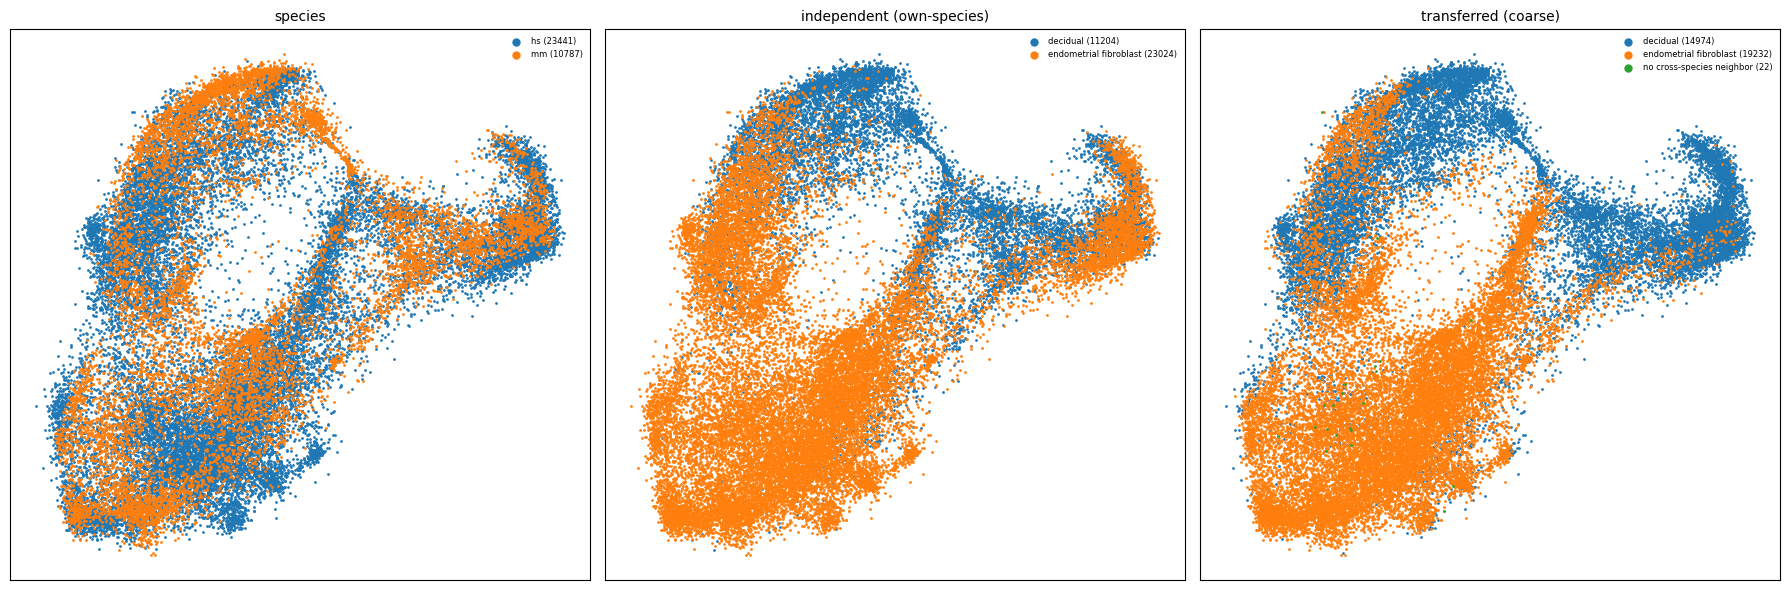

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
umap_cat(ax[0], a.obs["species"], "species", order=["hs","mm"])
umap_cat(ax[1], a.obs["cell_type_independent"], "independent (own-species)")
umap_cat(ax[2], a.obs["cell_type_transferred"], "transferred (coarse)")
plt.tight_layout(); plt.show()

## 2. Fine subtype — mouse native (left) vs transferred onto human (right)

Same palette both panels, so a color = the same mouse subtype in both. This is the fine transfer.

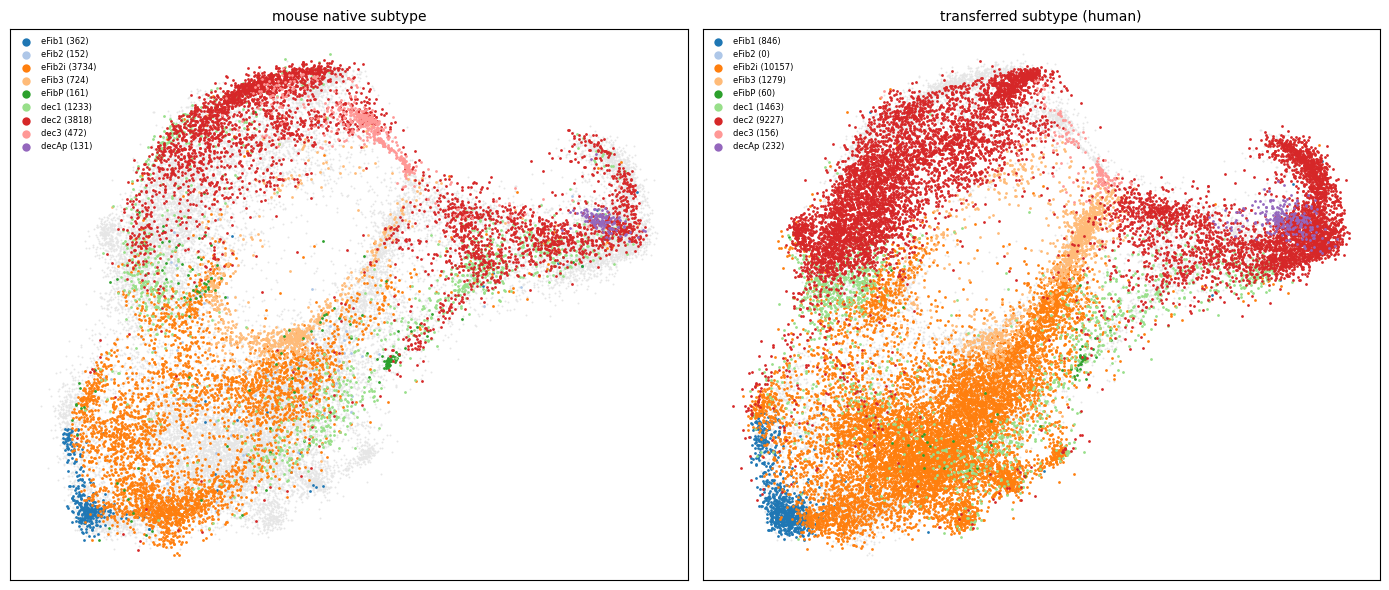

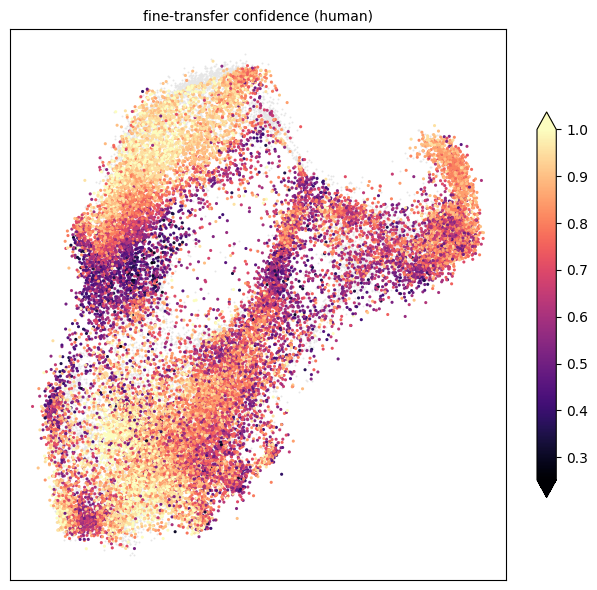

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
umap_cat(ax[0], a.obs["cell_subtype"], "mouse native subtype", mask=is_m,
         palette=SUB_COLORS, order=SUBTYPES)
umap_cat(ax[1], a.obs["cell_subtype_transferred"], "transferred subtype (human)", mask=is_h,
         palette=SUB_COLORS, order=SUBTYPES)
plt.tight_layout(); plt.show()

# transfer confidence (winning-subtype neighbor fraction) on human
fig, ax = plt.subplots(1, 1, figsize=(6.5, 6))
umap_cont(ax, a.obs["cell_subtype_transferred_frac"], "fine-transfer confidence (human)",
          mask=is_h, cmap="magma", clip=(0,100))
plt.tight_layout(); plt.show()

## 3. Pseudotime — native (mouse) + transferred (human), shared scale

`pseudotime_source` marks which is which. Shared p2–p98 across species so a color is the same
pseudotime value in both — the honest, comparable version.

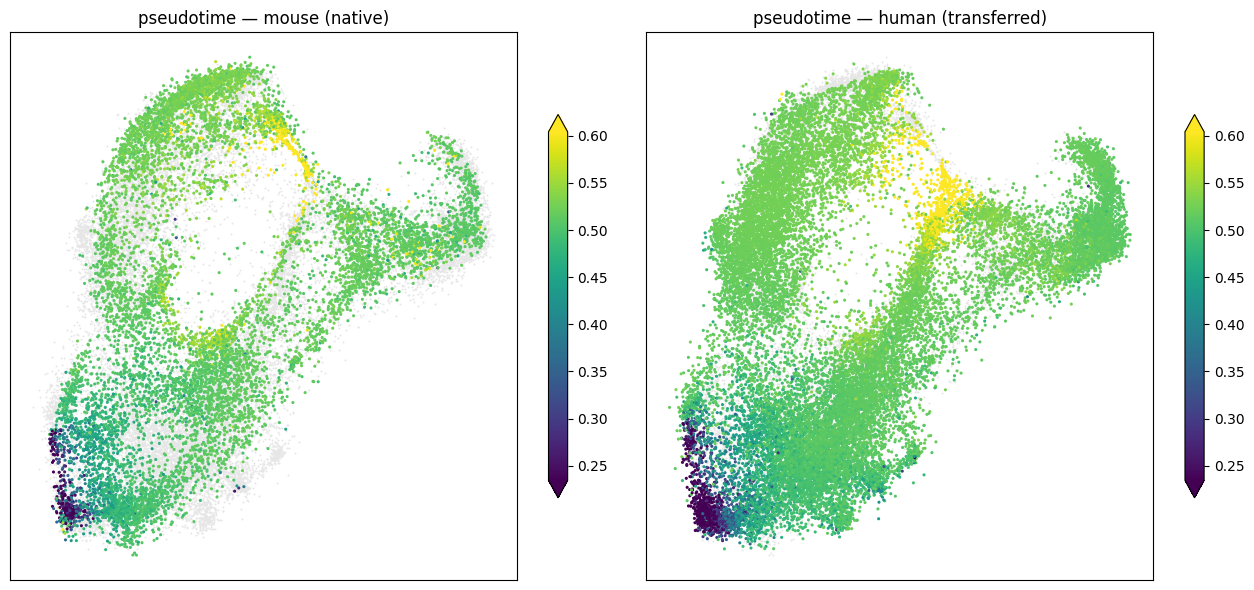

In [12]:
pt = a.obs["pseudotime"].values.astype(float)
fin = np.isfinite(pt)
vmin, vmax = np.percentile(pt[fin], (2, 98))       # shared scale across species

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for k, (nm, m) in enumerate([("mouse (native)", is_m), ("human (transferred)", is_h)]):
    keep = m & fin
    ax[k].scatter(U[~keep,0], U[~keep,1], s=2, color="0.9", linewidths=0, zorder=0)
    sc = ax[k].scatter(U[keep,0], U[keep,1], c=pt[keep], s=5, cmap="viridis",
                       vmin=vmin, vmax=vmax, linewidths=0)
    ax[k].set_title(f"pseudotime — {nm}"); ax[k].set_xticks([]); ax[k].set_yticks([])
    plt.colorbar(sc, ax=ax[k], shrink=0.7, extend="both")
plt.tight_layout(); plt.show()

## 4. Spatial — per species (coords are NOT co-registered; subset first)

Pseudotime on the tissue, mouse and human separately. `LABEL_MODE` switches what's colored.

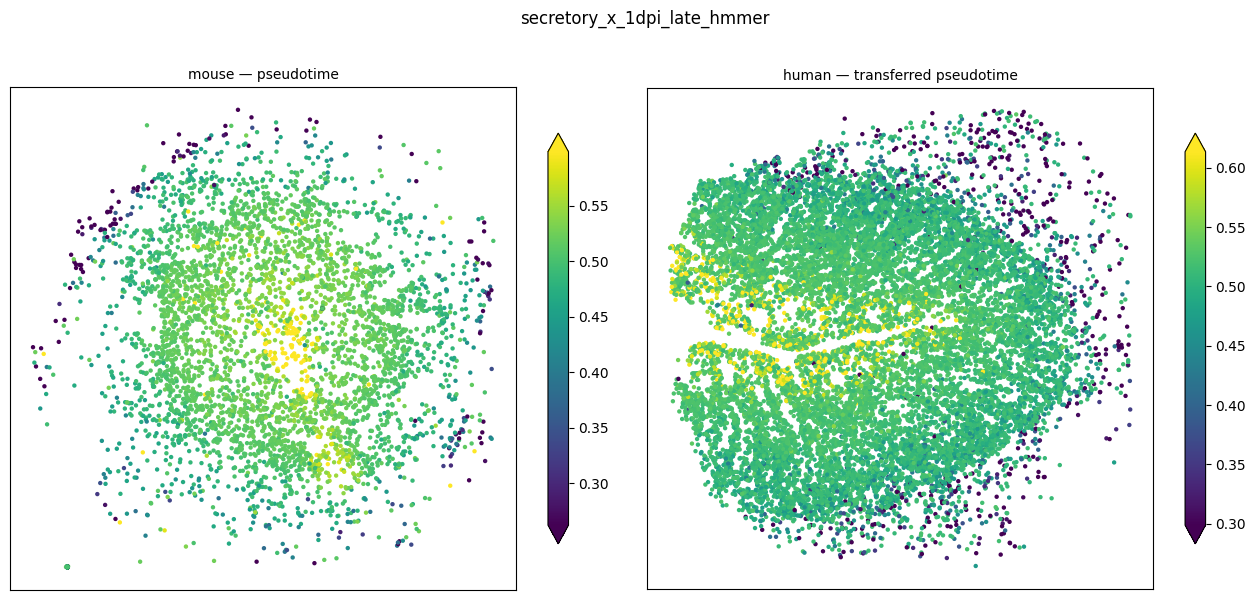

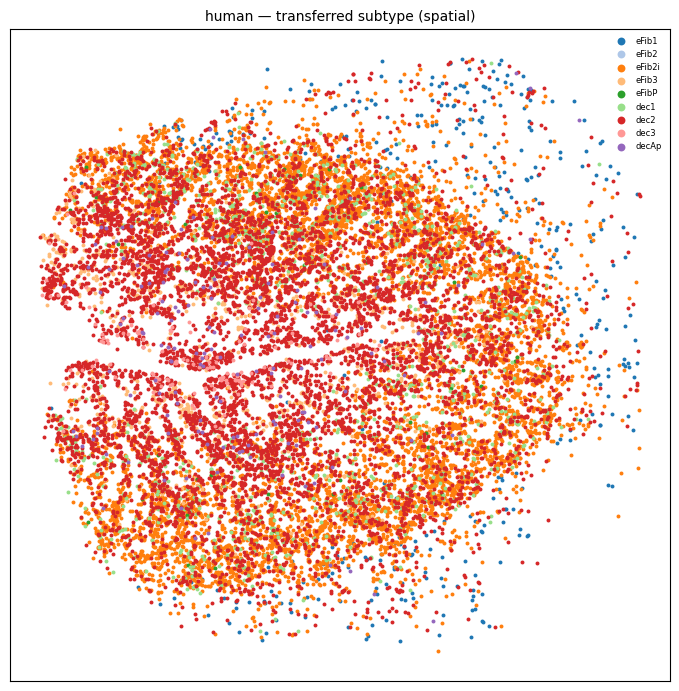

In [13]:
def spatial(ax, mask, color_vals, title, categorical=False, palette=None, order=None,
            cmap="viridis", clip=(2,98)):
    m = mask & np.isfinite(XY[:,0]) & np.isfinite(XY[:,1])
    ax.set_facecolor("white"); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=10)
    if categorical:
        v = pd.Series(np.asarray(color_vals, dtype=object)).astype(str).values
        for c in (order or sorted(set(v[m]) - {"","nan"})):
            mm = m & (v == c); ax.scatter(XY[mm,0], XY[mm,1], s=8,
                color=(palette.get(c) if palette else None), label=str(c), linewidths=0)
        ax.legend(markerscale=2, fontsize=6, frameon=False)
    else:
        v = np.asarray(color_vals, float); mm = m & np.isfinite(v)
        vmin, vmax = np.percentile(v[mm], clip)
        sc = ax.scatter(XY[mm,0], XY[mm,1], c=v[mm], s=10, cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0)
        plt.colorbar(sc, ax=ax, shrink=0.7, extend="both")

# pseudotime on tissue, both species
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5)); fig.patch.set_facecolor("white")
spatial(ax[0], is_m, a.obs["pseudotime"], "mouse — pseudotime")
spatial(ax[1], is_h, a.obs["pseudotime"], "human — transferred pseudotime")
plt.suptitle(RUN); plt.tight_layout(); plt.show()

# transferred fine subtype on human tissue
fig, ax = plt.subplots(1, 1, figsize=(7, 7)); fig.patch.set_facecolor("white")
spatial(ax, is_h, a.obs["cell_subtype_transferred"], "human — transferred subtype (spatial)",
        categorical=True, palette=SUB_COLORS, order=SUBTYPES)
plt.tight_layout(); plt.show()

## 5. Quick tables — the numbers behind the plots

In [14]:
for nm, m in [("HUMAN", is_h), ("MOUSE", is_m)]:
    print(f"=== {nm} ===")
    print(" coarse independent:", dict(a.obs.loc[m,"cell_type_independent"].value_counts()))
    print(" coarse transferred:", dict(a.obs.loc[m,"cell_type_transferred"].value_counts()))
print("\nhuman transferred FINE subtype:")
print(a.obs.loc[is_h,"cell_subtype_transferred"].value_counts().to_string())
print("\ncoarse independent vs transferred (human):")
print(pd.crosstab(a.obs.loc[is_h,"cell_type_independent"], a.obs.loc[is_h,"cell_type_transferred"]))

=== HUMAN ===
 coarse independent: {'endometrial fibroblast': np.int64(17891), 'decidual': np.int64(5550)}
 coarse transferred: {'endometrial fibroblast': np.int64(12265), 'decidual': np.int64(11155), 'no cross-species neighbor': np.int64(21)}
=== MOUSE ===
 coarse independent: {'decidual': np.int64(5654), 'endometrial fibroblast': np.int64(5133)}
 coarse transferred: {'endometrial fibroblast': np.int64(6967), 'decidual': np.int64(3819), 'no cross-species neighbor': np.int64(1)}

human transferred FINE subtype:
cell_subtype_transferred
eFib2i    10157
dec2       9227
dec1       1463
eFib3      1279
eFib1       846
decAp       232
dec3        156
eFibP        60
             21

coarse independent vs transferred (human):
cell_type_transferred   decidual  endometrial fibroblast  \
cell_type_independent                                      
decidual                    4323                    1227   
endometrial fibroblast      6832                   11038   

cell_type_transferred   no cr